# 06 · Your first model: `nn.Module`, loss functions and optimizers

**Objective:** To turn automatic differentiation (notebook 05) into a training procedure: fit a model to data by gradient descent, first by hand and then with `torch.nn` and `torch.optim`.

## Part 1: Concepts (90 mins)

### 1. The learning problem
We have data pairs $(x_i, y_i)$, $i = 1, \dots, N$, and a model $f_\theta(x)$ with parameters $\theta$. *Training* means choosing the $\theta$ that minimizes a **loss function**, for example the mean squared error

$$L(\theta) = \frac{1}{N} \sum_{i=1}^{N} \big(f_\theta(x_i) - y_i\big)^2 .$$

**Gradient descent** repeats one simple update, with a small step size $\eta$ called the *learning rate*:

$$\theta \leftarrow \theta - \eta \, \nabla_\theta L(\theta).$$

`autograd` computes $\nabla_\theta L$ for us. We start with the simplest model, a straight line $f(x) = w x + b$.

torch.Size([100, 1]) torch.Size([100, 1])


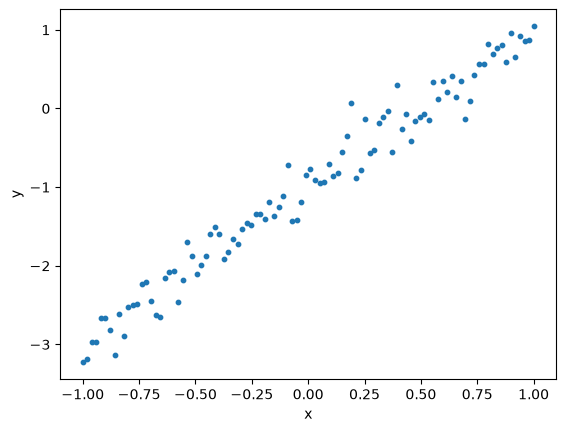

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)  # reproducible noise

true_w, true_b = 2.0, -1.0
X = torch.linspace(-1, 1, 100).unsqueeze(1)   # shape (100, 1): 100 samples, 1 feature
y = true_w * X + true_b + 0.2 * torch.randn(X.shape)

print(X.shape, y.shape)
plt.scatter(X, y, s=10)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

### 2. Gradient descent by hand
Three details matter:
- the parameter update is done inside `torch.no_grad()`, because the update itself must not become part of the computational graph;
- PyTorch **accumulates** gradients in `.grad`, so they must be reset to zero after every update;
- `loss.item()` converts a one-element tensor into a Python number (useful for logging).

w = 2.000 (true 2.0), b = -0.993 (true -1.0)


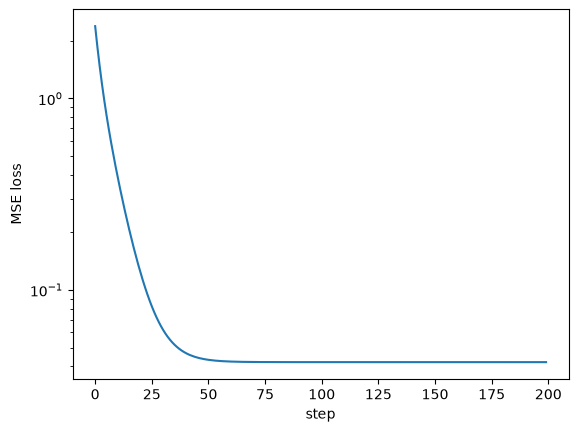

In [2]:
w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1
losses = []

for step in range(200):
    y_pred = X * w + b                   # forward pass
    loss = ((y_pred - y) ** 2).mean()    # mean squared error
    loss.backward()                      # compute dL/dw and dL/db

    with torch.no_grad():                # update the parameters
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()                       # reset the gradients
    b.grad.zero_()
    losses.append(loss.item())

print(f"w = {w.item():.3f} (true {true_w}), b = {b.item():.3f} (true {true_b})")

plt.plot(losses)
plt.xlabel("step")
plt.ylabel("MSE loss")
plt.yscale("log")
plt.show()

### 3. The same model with `torch.nn` and `torch.optim`
Writing every parameter and update by hand does not scale. PyTorch provides three building blocks:

- **`nn.Module`**: a class that holds the parameters and defines the `forward` computation;
- **loss functions** in `torch.nn`, e.g. `nn.MSELoss` for regression, `nn.CrossEntropyLoss` for classification;
- **optimizers** in `torch.optim`, e.g. `SGD` (the update above) or `Adam`.

In [3]:
import torch.nn as nn

class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)  # holds w and b

    def forward(self, x):
        return self.linear(x)

model = LinearRegression()
print(model)
for name, p in model.named_parameters():
    print(name, tuple(p.shape), "requires_grad =", p.requires_grad)

LinearRegression(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)
linear.weight (1, 1) requires_grad = True
linear.bias (1,) requires_grad = True


In [4]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(200):
    y_pred = model(X)             # forward pass
    loss = loss_fn(y_pred, y)     # compute loss
    optimizer.zero_grad()         # reset gradients
    loss.backward()               # backward pass
    optimizer.step()              # update parameters

print(f"w = {model.linear.weight.item():.3f}, b = {model.linear.bias.item():.3f}")

w = 2.000, b = -0.993


The correspondence with the manual version:

| By hand | With `torch.nn` / `torch.optim` |
|---|---|
| `X * w + b` | `model(X)` |
| `((y_pred - y) ** 2).mean()` | `loss_fn(y_pred, y)` |
| `w.grad.zero_()`, `b.grad.zero_()` | `optimizer.zero_grad()` |
| `w -= lr * w.grad` (inside `no_grad`) | `optimizer.step()` |

These five lines (forward, loss, zero_grad, backward, step) are the core of every training loop you will write.
Here each step uses the whole dataset (*full-batch* gradient descent); notebooks 07 and 08 split the data into mini-batches.

### 4. Beyond straight lines: a small neural network
A linear model cannot fit a curved relationship: whatever $w$ and $b$ we choose, $wx + b$ is a straight line. Below we try to fit noisy data around $y = \sin(3x)$. We need a model that can **bend**.

A **multi-layer perceptron (MLP)** is the simplest neural network that can do it. It is built from a few components, which we go through one at a time:

1. **linear layers** (`nn.Linear`), which mix their inputs with weights and biases;
2. **activation functions** (here `nn.Tanh`), which bend;
3. the **architecture**: how many layers, and how wide;
4. **`nn.Sequential`**, which chains the layers into one model;
5. the **training loop**, the same as in section 3, here with the `Adam` optimizer.

#### Component 1: the linear layer `nn.Linear(in_features, out_features)`
It is the generalisation of $wx + b$ to several inputs and several outputs. For one sample $\mathbf{x}$ with `in_features` numbers, it computes `out_features` numbers:
$$\mathbf{h} = W\mathbf{x} + \mathbf{b}, \qquad W \text{ of shape (out, in)}, \quad \mathbf{b} \text{ of shape (out)}.$$
Each output $h_j = \sum_k W_{jk} x_k + b_j$ is a weighted sum of *all* the inputs plus a bias: this is what is called a **neuron**, and `out_features` is the number of neurons of the layer. With a batch of $N$ samples stored as rows of a matrix of shape `(N, in)`, the layer processes all rows at once and returns shape `(N, out)` (in matrix form, $X W^\top + \mathbf{b}$, with broadcasting of $\mathbf{b}$ as in notebook 01).

`nn.Linear(1, 1)` is exactly the `LinearRegression` of section 3. The weights are **initialised at random** (small values, uniform between $\pm 1/\sqrt{\text{in}}$). This is why we call `torch.manual_seed` before creating a model: same seed, same starting point, same result. (If all weights started equal, all neurons would compute the same thing and receive the same updates: they would stay identical forever.)

#### Component 2: the activation function
`nn.Tanh()` applies $\tanh$ to **each number separately**: the shape does not change, and every value is squashed into $(-1, 1)$ along an S-shaped curve. It has no parameters.

**Why is it needed?** Two linear layers in a row are still one linear layer:
$$W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = \underbrace{(W_2 W_1)}_{W}\,\mathbf{x} + \underbrace{(W_2\mathbf{b}_1 + \mathbf{b}_2)}_{\mathbf{b}}.$$
However many we stack, the model can only draw straight lines (or planes). Putting a non-linear function between them breaks this collapse, and lets the network build curved functions. Common choices: **ReLU**, $\max(0, x)$, the default in most modern networks (`nn.ReLU`); **tanh**, smooth, a good choice for smooth targets like ours; **sigmoid**, $1/(1+e^{-x})$, squashes into $(0, 1)$.

#### Component 3: the architecture
Our MLP transforms each sample as follows (shapes for the whole batch of 200 points):

| Layer | Output shape | Parameters |
|---|---|---|
| input | `(200, 1)` | |
| `nn.Linear(1, 32)` | `(200, 32)` | $32 \times 1$ weights $+ 32$ biases $= 64$ |
| `nn.Tanh()` | `(200, 32)` | 0 |
| `nn.Linear(32, 32)` | `(200, 32)` | $32 \times 32 + 32 = 1056$ |
| `nn.Tanh()` | `(200, 32)` | 0 |
| `nn.Linear(32, 1)` | `(200, 1)` | $1 \times 32 + 1 = 33$ |
| **total** | | **1153** |

The first and the last sizes are fixed by the problem (1 input feature, 1 output value), and the `out_features` of each layer must equal the `in_features` of the next one. The layers in between are **hidden layers**: their number (the *depth*) and size (the *width*, here 32) are choices, called *hyperparameters*. Lab 6.3 explores the effect of the width.

#### Component 4: `nn.Sequential`
`nn.Sequential(layer1, layer2, ...)` is a ready-made `nn.Module` whose `forward` simply passes the input through the layers **in order**. It is equivalent to writing a class as in section 3:
```python
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(1, 32)
        self.layer2 = nn.Linear(32, 32)
        self.layer3 = nn.Linear(32, 1)
        self.act = nn.Tanh()
    def forward(self, x):
        x = self.act(self.layer1(x))
        x = self.act(self.layer2(x))
        return self.layer3(x)
```
`nn.Sequential` is shorter when the data just flows through a chain; a class is needed when the computation is not a simple chain. The layers of a `Sequential` can be accessed by position (`mlp[0]` is the first `Linear`, `mlp[:4]` the first four layers), and its parameters are named after the positions: `0.weight`, `0.bias`, `2.weight`...

#### Component 5: training
The `train` function below contains the same five lines as section 3 (forward, loss, `zero_grad`, `backward`, `step`), run 2000 times on the whole dataset. One difference and one remark:
* we use **`torch.optim.Adam`** instead of `SGD`. Adam is gradient descent with two improvements: it keeps a running average of the past gradients (*momentum*: steps keep their direction instead of zig-zagging), and it gives **each parameter its own step size**, rescaled by the typical size of that parameter's gradients. In practice it works well with little tuning (`lr` between 0.001 and 0.01 is a good start). Lab 6.2 compares it with SGD;
* in section 2 we reset the gradients *after* the update, here (as in section 3) `optimizer.zero_grad()` comes just *before* `backward()`. Both are correct: what matters is that the gradients are reset once per step, between one `backward()` and the next.

In [5]:
torch.manual_seed(0)
X_curve = torch.linspace(-2, 2, 200).unsqueeze(1)                    # shape (200, 1)
y_curve = torch.sin(3 * X_curve) + 0.1 * torch.randn(X_curve.shape)  # noisy sine, shape (200, 1)

def train(model, X, y, optimizer, n_steps=2000):
    # Full-batch training with MSE; returns the list of losses.
    loss_fn = nn.MSELoss()
    losses = []
    for step in range(n_steps):
        loss = loss_fn(model(X), y)   # forward pass + loss
        optimizer.zero_grad()         # reset the gradients of the previous step
        loss.backward()               # compute the gradient of the loss for every parameter
        optimizer.step()              # update every parameter
        losses.append(loss.item())    # keep a Python number for the plot
    return losses

torch.manual_seed(1)                  # same random initial weights at every run
linear_model = nn.Linear(1, 1)        # the straight line, for comparison
mlp = nn.Sequential(
    nn.Linear(1, 32), nn.Tanh(),      # hidden layer 1: 32 neurons, then tanh
    nn.Linear(32, 32), nn.Tanh(),     # hidden layer 2: 32 neurons, then tanh
    nn.Linear(32, 1),                 # output layer: one number per sample
)
print(mlp)
print("Number of parameters:", sum(p.numel() for p in mlp.parameters()))   # numel = number of elements

losses_linear = train(linear_model, X_curve, y_curve, torch.optim.Adam(linear_model.parameters(), lr=0.01))
losses_mlp = train(mlp, X_curve, y_curve, torch.optim.Adam(mlp.parameters(), lr=0.01))
print(f"final loss: linear {losses_linear[-1]:.4f}, MLP {losses_mlp[-1]:.4f}")

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Number of parameters: 1153
final loss: linear 0.4459, MLP 0.0081


**Looking inside the trained network.** The next cell follows the data through the layers, printing the shape after each one (the table of Component 3). Then it shows *how* the MLP builds its curve: the last layer is just a `Linear(32, 1)`, so the output is a **weighted sum of the 32 curves** computed by the second hidden layer, plus a bias. Each of those curves is a smooth S-shaped piece; training has adjusted the weights so that, added together, they reproduce the sine.

input             (200, 1)
after mlp[0] Linear  (200, 32)
after mlp[1] Tanh    (200, 32)
after mlp[2] Linear  (200, 32)
after mlp[3] Tanh    (200, 32)
after mlp[4] Linear  (200, 1)
weighted sum of the hidden curves == mlp(X): True


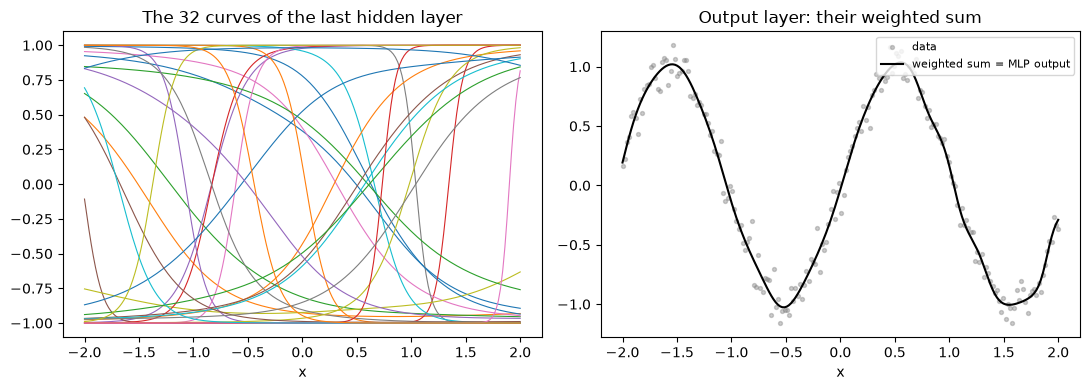

In [6]:
# 1. Follow a batch through the layers
h = X_curve
print("input            ", tuple(h.shape))
for i, layer in enumerate(mlp):
    h = layer(h)
    print(f"after mlp[{i}] {layer.__class__.__name__:<7}", tuple(h.shape))

# 2. The 32 outputs of the last hidden layer, and the final output built from them
with torch.no_grad():
    hidden = mlp[:4](X_curve)                                 # shape (200, 32): first four layers only
    output = hidden @ mlp[4].weight.T + mlp[4].bias           # what mlp[4] = Linear(32, 1) computes
print("weighted sum of the hidden curves == mlp(X):", torch.allclose(output, mlp(X_curve).detach()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(X_curve, hidden, linewidth=0.8)
ax1.set_title("The 32 curves of the last hidden layer")
ax1.set_xlabel("x")
ax2.scatter(X_curve, y_curve, s=8, alpha=0.4, color="gray", label="data")
ax2.plot(X_curve, output, "k", label="weighted sum = MLP output")
ax2.set_title("Output layer: their weighted sum")
ax2.set_xlabel("x")
ax2.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

**Comparing the two models.** To draw the fitted curves we evaluate the trained models on `X_curve` inside `torch.no_grad()`: we only need the predictions, not gradients, so there is no reason to build a computation graph (and Matplotlib cannot plot tensors that require gradients). The left plot shows the data and the two fits, the right plot the loss during training, on a logarithmic scale.

The line ends at a loss of about 0.45: the best straight line through a sine wave. The MLP reaches about 0.008, close to $0.1^2 = 0.01$, the variance of the noise we added to the data. That is about as good as any model can do on average: the remaining error is the noise itself, which no model can predict.

In [ ]:
with torch.no_grad():
    fit_linear = linear_model(X_curve)
    fit_mlp = mlp(X_curve)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(X_curve, y_curve, s=8, alpha=0.5, label="data")
ax1.plot(X_curve, fit_linear, "r", label="linear")
ax1.plot(X_curve, fit_mlp, "k", label="MLP")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.legend()

ax2.plot(losses_linear, label="linear")
ax2.plot(losses_mlp, label="MLP")
ax2.set_yscale("log")
ax2.set_xlabel("step")
ax2.set_ylabel("MSE loss")
ax2.legend()
plt.tight_layout()
plt.show()

**A word of caution.** A low *training* loss only says that the model fits the data it has seen. Whether it works on new data must be measured on data held out from training: this is the subject of notebook 09.

## Part 2: Exercises & Debugging (90 mins)

### Lab 6.1: The learning rate
* **Task:** Train the `LinearRegression` model on `(X, y)` with `SGD` for 100 steps, for each learning rate in `[0.001, 0.01, 0.1, 0.5, 1.2]`. Store the loss curves and plot them on the same axes (log scale on the y axis).
* **Questions:** Which learning rates are too small? What happens with `lr=1.2`?
* **Hint:** call `torch.manual_seed(0)` before creating each model, so that all runs start from the same initial parameters.

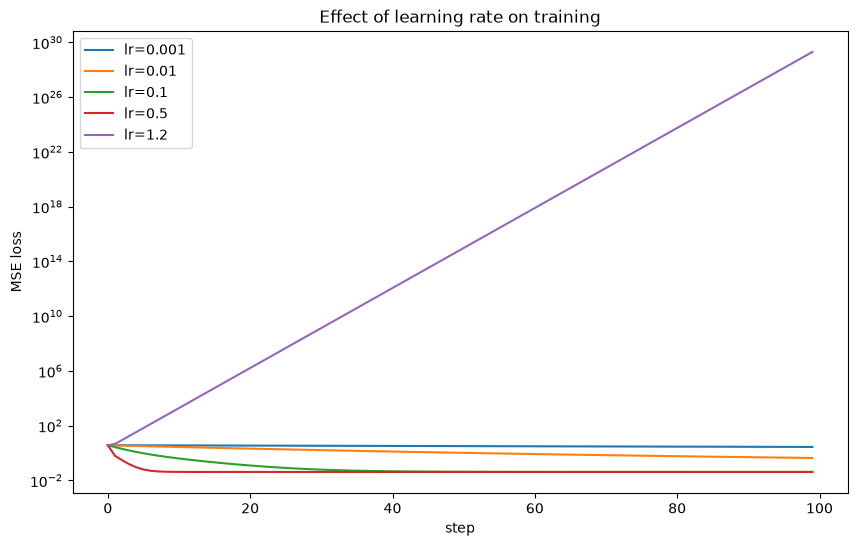

In [10]:
#your code here
import torch

import torch.nn as nn
import matplotlib.pyplot as plt


#definition of the LinearRegression class
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        return self.linear(x)

# train with different learning rates
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.2]
loss_curves = {}

for lr in learning_rates:
    torch.manual_seed(0)  # same initialization for a fair comparison
    model = LinearRegression()
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    losses = []
    for step in range(100):
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    loss_curves[lr] = losses

# Plot all curves on the same axes, log scale on y
plt.figure(figsize=(10, 6))
for lr, losses in loss_curves.items():
    plt.plot(losses, label=f"lr={lr}")

plt.yscale("log")
plt.xlabel("step")
plt.ylabel("MSE loss")
plt.title("Effect of learning rate on training")
plt.legend()
plt.show()

### Lab 6.2: Choosing the optimizer
* **Task:** Fit the curve data `(X_curve, y_curve)` with the same MLP architecture, once with `SGD(lr=0.1)` and once with `Adam(lr=0.01)`, for 2000 steps each. Start both from the same initialization and compare the loss curves.

Final loss — SGD: 0.0166, Adam: 0.0083


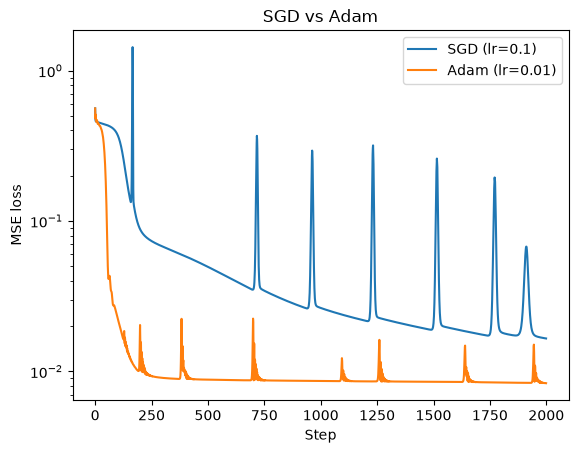

In [9]:
# Your code here
def make_mlp():
    return nn.Sequential(
        nn.Linear(1, 32), nn.Tanh(),
        nn.Linear(32, 32), nn.Tanh(),
        nn.Linear(32, 1),
    )

torch.manual_seed(1)
mlp_sgd = make_mlp()
torch.manual_seed(1)
mlp_adam = make_mlp()

losses_sgd = train(
    mlp_sgd, X_curve, y_curve,
    torch.optim.SGD(mlp_sgd.parameters(), lr=0.1),
    n_steps=2000,
)
losses_adam = train(
    mlp_adam, X_curve, y_curve,
    torch.optim.Adam(mlp_adam.parameters(), lr=0.01),
    n_steps=2000,
)

print(f"Final loss — SGD: {losses_sgd[-1]:.4f}, Adam: {losses_adam[-1]:.4f}")

plt.plot(losses_sgd, label="SGD (lr=0.1)")
plt.plot(losses_adam, label="Adam (lr=0.01)")
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("MSE loss")
plt.title("SGD vs Adam")
plt.legend()
plt.show()

### Lab 6.3: How big should the network be?
* **Task:** Train MLPs with hidden sizes `[2, 8, 32, 128]` on the curve data (Adam, `lr=0.01`, 2000 steps) and plot the four fitted curves on top of the data. Print the number of parameters of each model.
* **Question:** The training loss keeps decreasing as the model grows. Does that mean the largest model is the best one? What would you need to answer this question?

Hidden size   2:     13 parameters, final loss 0.0541
Hidden size   8:     97 parameters, final loss 0.0086
Hidden size  32:   1153 parameters, final loss 0.0083
Hidden size 128:  16897 parameters, final loss 0.0079


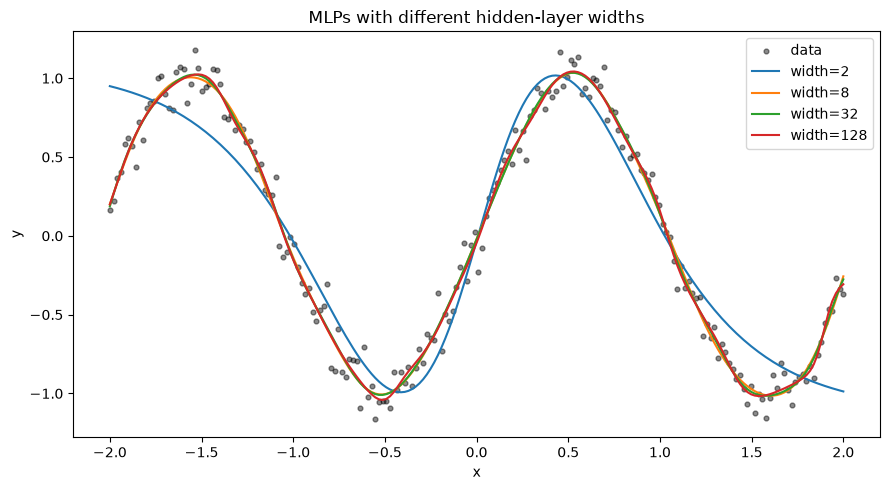

In [ ]:
#your code here
hidden_sizes = [2, 8, 32, 128]
models_by_size = {}
losses_by_size = {}

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_curve.detach().numpy(), y_curve.detach().numpy(),
           s=12, alpha=0.45, color="black", label="data")

for size in hidden_sizes:
    torch.manual_seed(1)  # consistent initialization across runs
    model = nn.Sequential(
        nn.Linear(1, size), nn.Tanh(),
        nn.Linear(size, size), nn.Tanh(),
        nn.Linear(size, 1),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    losses = train(model, X_curve, y_curve, optimizer, n_steps=2000)

    models_by_size[size] = model
    losses_by_size[size] = losses

    n_params = sum(p.numel() for p in model.parameters())
    print(f"Hidden size {size:>3}: {n_params:>6} parameters, "
          f"final loss {losses[-1]:.4f}")

    with torch.no_grad():
        prediction = model(X_curve)
    ax.plot(X_curve.detach().numpy(), prediction.detach().numpy(),
            label=f"width={size}")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("MLPs with different hidden-layer widths")
ax.legend()
plt.tight_layout()
plt.show()

### Debugging Focus 1: Forgetting `zero_grad()`
- **The Problem:** The loss behaves erratically or diverges, even with a reasonable learning rate.
- **The Cause:** `backward()` *adds* the new gradient to whatever is already stored in `.grad`. Without `optimizer.zero_grad()`, each step uses the sum of all past gradients.

In [ ]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    loss = 4.5 * w ** 2        # dloss/dw = 9 w = 9 at w = 1
    loss.backward()
    print(f"after backward #{i + 1}: w.grad = {w.grad.item()}")   # 9, 18, 27: accumulated!

### Debugging Focus 2: Silent broadcasting between predictions and targets
- **The Problem:** Training runs without errors, but the model does not learn.
- **The Cause:** The model outputs shape `(N, 1)`, while the targets have shape `(N,)`. Subtracting them broadcasts to an `(N, N)` matrix, so the loss compares every prediction with every target.
- **The Solution:** Always print the shapes of predictions and targets. Keep them identical, e.g. with `y.unsqueeze(1)` or `pred.squeeze(1)`. `nn.MSELoss` prints a `UserWarning` in this situation: do not ignore warnings.

In [ ]:
model = LinearRegression()
pred = model(X)             # shape (100, 1)
y_flat = y.squeeze(1)       # shape (100,)
print("pred:", pred.shape, " target:", y_flat.shape, " difference:", (pred - y_flat).shape)
loss = nn.MSELoss()(pred, y_flat)   # look at the warning below